Simulation took 0.27339935302734375 seconds
{'grid_building_time': 9.914e-06, 'num_collisions': 204090, 'num_crossings': 4637174, 'total_time': 0.263925689, 'trace_time': 0.263915775}


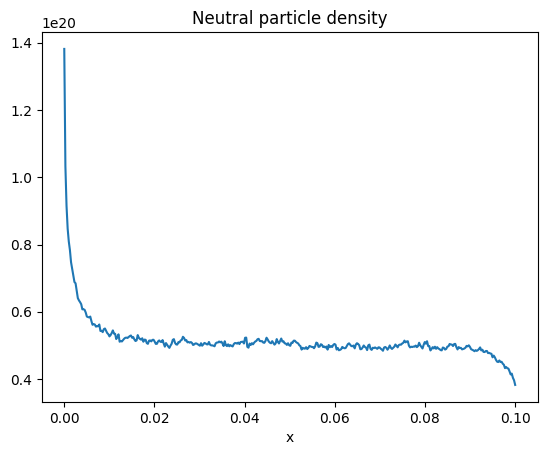

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import math
import json
import subprocess
import time

config = {}

Lx = 0.1
Ly = 0.1
Lz = 0.1
nx = 400
ny = 1
nz = 1

config["mesh"] = {
    "type": "voxel",
    "Lx": Lx,
    "Ly": Ly,
    "Lz": Lz,
    "nx": nx,
    "ny": ny,
    "nz": nz
}

ncells = nx * ny * nz

plasma_dens = np.zeros(ncells, dtype=np.float64)
plasma_temp = np.zeros(ncells, dtype=np.float64)
plasma_vel_x = np.zeros(ncells, dtype=np.float64)
plasma_vel_y = np.zeros(ncells, dtype=np.float64)
plasma_vel_z = np.zeros(ncells, dtype=np.float64)

for i in range(ncells):
    plasma_dens[i] = 1.0e20

for i in range(ncells):
    plasma_temp[i] = 1.0

for i in range(ncells):
    plasma_vel_x[i] = 1.0e4

config["background"] = {
    "plasma_dens": plasma_dens.tolist(),
    "plasma_temp": plasma_temp.tolist(),
    "plasma_vel_x": plasma_vel_x.tolist(),
    "plasma_vel_y": plasma_vel_y.tolist(),
    "plasma_vel_z": plasma_vel_z.tolist()
}


config["sources"] = [
    {
        "type": "line",
        "intensity": 5.0e21,
        "pos_a": [0, 0, 0],
        "pos_b": [0, 0.1, 0],
        "n_particles": 10000,
    }
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "absorbing",
    "reflective",
    "reflective"
]

config["max_steps"] = 1000
config["seed"] = 0
inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["eigrene-json"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"])

x = np.linspace(0,Lx,nx)

plt.plot(x, neutral_density)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.show()
